## Importando Bibliotecas e Carregando os Dados

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

In [3]:
caminho_atual = Path(".").resolve()
pasta_dados = caminho_atual.parent / "data"
pasta_dados_raw = pasta_dados / "raw"
pasta_dados_processed = pasta_dados / "processed"


df_train = pd.read_csv(pasta_dados_processed / "train_processed.csv")
df_test = pd.read_csv(pasta_dados / "processed" / "test_processed.csv")

df_train_scaled = pd.read_csv(pasta_dados_processed / "train_scaled.csv")
df_test_scaled = pd.read_csv(pasta_dados_processed / "test_scaled.csv")

# Bases originais para análise de erros e montagem do arquivo final de entrega
df_train_raw = pd.read_csv(pasta_dados_raw / "train.csv")
df_test_raw = pd.read_csv(pasta_dados_raw / "test.csv")

print(f"Treino processado: {df_train.shape}")
print(f"Teste processado:  {df_test.shape}")

Treino processado: (712, 27)
Teste processado:  (179, 26)


## 1. Estratégia de Validação

- Separamos os dados de treino em **80% Treino (569 linhas)** e **20% Validação (143 linhas)** usando amostragem estratificada (`stratify=y`) para manter a mesma proporção de sobreviventes (~38%).
- Além da validação hold-out, usamos **Validação Cruzada Estratificada de 5 Folds (`StratifiedKFold`)** para avaliar a estabilidade dos modelos em diferentes divisões.

In [5]:
X = df_train.drop(columns=["Survived"])
y = df_train["Survived"]

X_scaled = df_train_scaled.drop(columns=["Survived"])

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_tr_sc, X_val_sc, _, _ = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Treino: {X_tr.shape[0]} amostras | Validação: {X_val.shape[0]} amostras")
print(f"Proporção de Survived no Treino: {y_tr.mean():.2%} | na Validação: {y_val.mean():.2%}")

Treino: 569 amostras | Validação: 143 amostras
Proporção de Survived no Treino: 38.31% | na Validação: 38.46%


## 2. Mineração de Dados: Treinamento e Comparação de Modelos

Treinamos 5 algoritmos de classificação com controle de profundidade para evitar *overfitting*:
1. **Logistic Regression** (usando a base padronizada `scaled`)
2. **Decision Tree** (árvore simples como baseline)
3. **Random Forest** (ensemble por *bagging*)
4. **Gradient Boosting** (ensemble por *boosting* sequencial)
5. **XGBoost** (*boosting* regularizado)

**Métricas avaliadas:** `Accuracy`, `Precision`, `Recall`, `F1-Score` (essencial pois as classes são desbalanceadas: 62% não sobreviveram vs 38% sobreviveram) e `ROC-AUC`.

In [22]:
modelos = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=3, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42, eval_metric="logloss")
}

In [23]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = []
previsoes_val = {}

for nome, modelo in modelos.items():
    # Usa os dados padronizados apenas para a Regressão Logística
    if nome == "Logistic Regression":
        x_treino, x_valid, x_completo = X_tr_sc, X_val_sc, X_scaled
    else:
        x_treino, x_valid, x_completo = X_tr, X_val, X

    modelo.fit(x_treino, y_tr)
    y_pred = modelo.predict(x_valid)
    y_prob = modelo.predict_proba(x_valid)[:, 1]
    previsoes_val[nome] = y_pred

    cv_acc = cross_val_score(modelo, x_completo, y, cv=kfold, scoring="accuracy").mean()
    cv_f1 = cross_val_score(modelo, x_completo, y, cv=kfold, scoring="f1").mean()

    resultados.append({
        "Modelo": nome,
        "CV Accuracy (5-Fold)": round(cv_acc, 4),
        "CV F1-Score (5-Fold)": round(cv_f1, 4),
        "Val Accuracy": round(accuracy_score(y_val, y_pred), 4),
        "Val Precision": round(precision_score(y_val, y_pred), 4),
        "Val Recall": round(recall_score(y_val, y_pred), 4),
        "Val F1-Score": round(f1_score(y_val, y_pred), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val, y_prob), 4)
    })

df_resultados = pd.DataFrame(resultados).sort_values(by="CV F1-Score (5-Fold)", ascending=False)
display(df_resultados)

,Modelo,CV Accuracy (5-Fold),CV F1-Score (5-Fold),Val Accuracy,Val Precision,Val Recall,Val F1-Score,Val ROC-AUC
2,Random Forest,0.8357,0.7739,0.8252,0.7778,0.7636,0.7706,0.9045
0,Logistic Regression,0.8273,0.7717,0.8182,0.7544,0.7818,0.7679,0.8630
4,XGBoost,0.8343,0.7700,0.8042,0.7455,0.7455,0.7455,0.8970
3,Gradient Boosting,0.8259,0.7607,0.7972,0.7407,0.7273,0.7339,0.9008
1,Decision Tree,0.8146,0.7500,0.8392,0.7857,0.8000,0.7928,0.8881


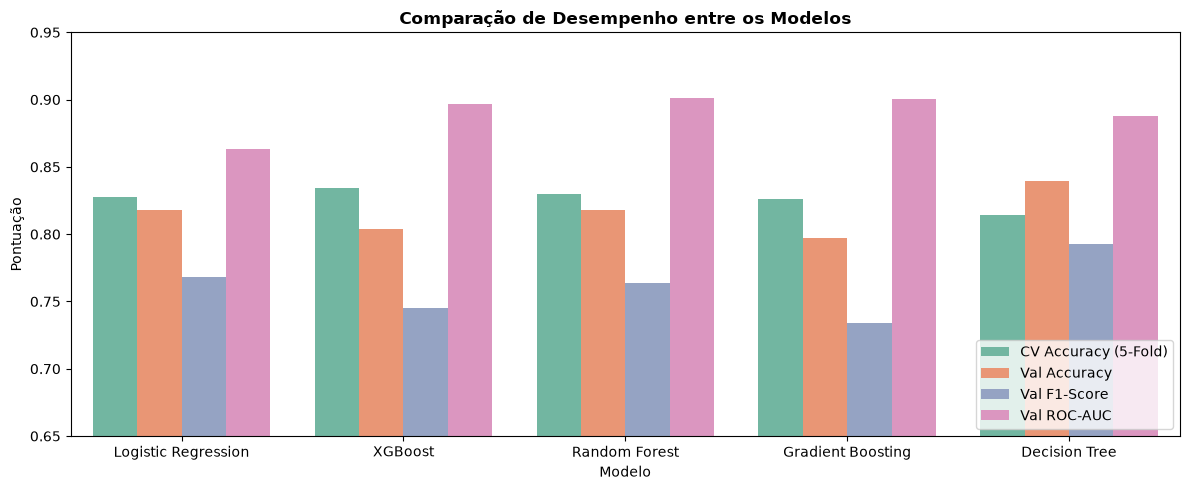

In [6]:
metricas_plot = df_resultados.melt(
    id_vars="Modelo",
    value_vars=["CV Accuracy (5-Fold)", "Val Accuracy", "Val F1-Score", "Val ROC-AUC"],
    var_name="Métrica",
    value_name="Valor"
)

plt.figure(figsize=(12, 5))
sns.barplot(data=metricas_plot, x="Modelo", y="Valor", hue="Métrica", palette="Set2")
plt.title("Comparação de Desempenho entre os Modelos", fontweight="bold")
plt.ylim(0.65, 0.95)
plt.ylabel("Pontuação")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 3. Avaliação: Matrizes de Confusão

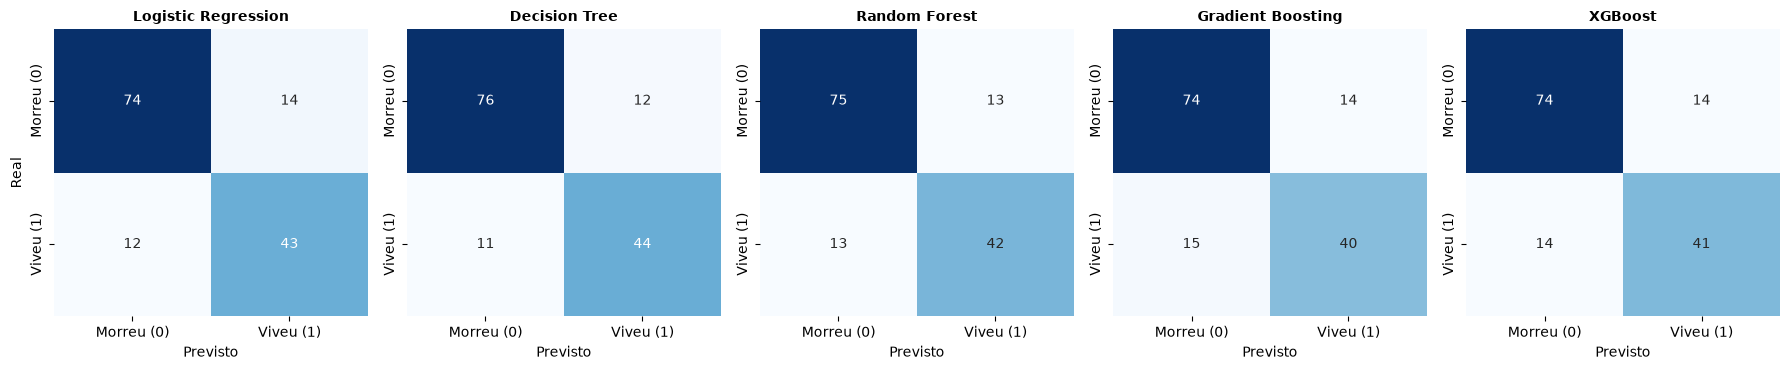

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=len(modelos), figsize=(18, 3.8))

for i, (nome, y_pred) in enumerate(previsoes_val.items()):
    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i],
        xticklabels=["Morreu (0)", "Viveu (1)"],
        yticklabels=["Morreu (0)", "Viveu (1)"]
    )
    axes[i].set_title(nome, fontweight="bold", fontsize=10)
    axes[i].set_xlabel("Previsto")
    if i == 0:
        axes[i].set_ylabel("Real")

plt.tight_layout()
plt.show()

## 4. Interpretação do Comportamento do Modelo (Feature Importance)

Analisamos quais variáveis tiveram maior peso nas decisões dos modelos de árvore:

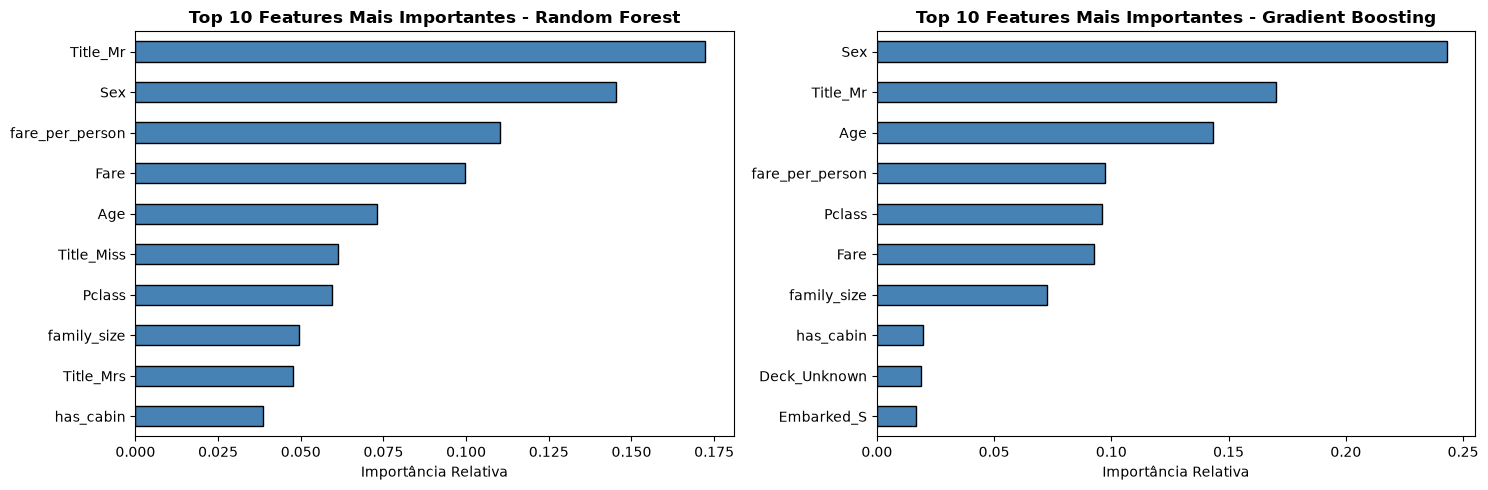

In [8]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

for i, nome_mod in enumerate(["Random Forest", "Gradient Boosting"]):
    importancias = pd.Series(modelos[nome_mod].feature_importances_, index=X.columns)
    top_10 = importancias.sort_values(ascending=True).tail(10)
    top_10.plot(kind="barh", color="steelblue", edgecolor="black", ax=axes[i])
    axes[i].set_title(f"Top 10 Features Mais Importantes - {nome_mod}", fontweight="bold")
    axes[i].set_xlabel("Importância Relativa")

plt.tight_layout()
plt.show()

## 5. Análise de Erros

Inspecionamos os passageiros do conjunto de validação em que o modelo errou a previsão:
- **Falsos Positivos (`Real = 0`, `Previsto = 1`):** Passageiros que tinham perfil favorável à sobrevivência (ex: mulheres ou passageiros de classes superiores/tarifas maiores), mas acabaram não sobrevivendo.
- **Falsos Negativos (`Real = 1`, `Previsto = 0`):** Passageiros com baixa probabilidade histórica (ex: homens adultos `Mr` na 3ª ou 2ª classe viajando sozinhos), mas que conseguiram sobreviver.

In [9]:
melhor_nome = df_resultados.iloc[0]["Modelo"]
y_pred_melhor = previsoes_val[melhor_nome]

df_analise_erros = df_train_raw.loc[X_val.index, ["Pclass", "Name", "Sex", "Age", "siblings", "Parch", "Fare", "Survived"]].copy()
df_analise_erros["Fare"] = X_val["Fare"]
df_analise_erros["Previsto"] = y_pred_melhor

falsos_positivos = df_analise_erros[(df_analise_erros["Survived"] == 0) & (df_analise_erros["Previsto"] == 1)]
falsos_negativos = df_analise_erros[(df_analise_erros["Survived"] == 1) & (df_analise_erros["Previsto"] == 0)]

print(f"Modelo analisado: {melhor_nome}")
print(f"Total de Falsos Positivos: {len(falsos_positivos)} | Total de Falsos Negativos: {len(falsos_negativos)}")

print("\nExemplos de Falsos Positivos (Previu que sobreviveu, mas morreu):")
display(falsos_positivos.head(5))

print("\nExemplos de Falsos Negativos (Previu que morreu, mas sobreviveu):")
display(falsos_negativos.head(5))

Modelo analisado: Logistic Regression
Total de Falsos Positivos: 14 | Total de Falsos Negativos: 12

Exemplos de Falsos Positivos (Previu que sobreviveu, mas morreu):


,Pclass,Name,Sex,Age,siblings,Parch,Fare,Survived,Previsto
522,3,"Hegarty, Miss. Hanora ""Nora""",female,18.0,0,0,6.7500,0,1
308,1,"Widener, Mr. Harry Elkins",male,27.0,0,2,211.5000,0,1
584,3,"Ilmakangas, Miss. Pieta Sofia",female,25.0,1,0,7.9250,0,1
305,1,"Ringhini, Mr. Sante",male,22.0,0,0,135.6333,0,1
86,3,"Zabour, Miss. Hileni",female,14.5,1,0,14.4542,0,1



Exemplos de Falsos Negativos (Previu que morreu, mas sobreviveu):


,Pclass,Name,Sex,Age,siblings,Parch,Fare,Survived,Previsto
319,3,"Jansson, Mr. Carl Olof",male,21.0,0,0,7.7958,1,0
54,3,"Andersson, Miss. Erna Alexandra",female,17.0,4,2,7.9250,1,0
479,1,"Homer, Mr. Harry (""Mr E Haven"")",male,35.0,0,0,26.5500,1,0
527,1,"Frauenthal, Dr. Henry William",male,50.0,2,0,133.6500,1,0
365,1,"Goldenberg, Mr. Samuel L",male,49.0,1,0,89.1042,1,0


## 6. Justificativa do Modelo Final e Inferência no `test.csv`

- O modelo escolhido como final é treinado agora com **100% dos 712 registros de treinamento** para aproveitar todos os dados disponíveis.
- Em seguida, geramos o arquivo `test_inferred.csv` preservando exatamente as 179 observações e a mesma ordem do arquivo `test.csv`.

In [ ]:
print(f"Modelo Final selecionado: {melhor_nome}")
modelo_final = modelos[melhor_nome]

if melhor_nome == "Logistic Regression":
    modelo_final.fit(X_scaled, y)
    previsoes_teste = modelo_final.predict(df_test_scaled)
else:
    modelo_final.fit(X, y)
    previsoes_teste = modelo_final.predict(df_test)

# Monta o dataframe de entrega mantendo a ordem e as 179 linhas originais do test.csv
df_entrega = df_test_raw.copy()
df_entrega["Survived"] = previsoes_teste

# Salva na pasta data/ e na raiz do projeto para entrega
df_entrega.to_csv(pasta_dados / "inferred" / "test_inferred.csv", index=False)

print(f"Total de observações em test_inferred.csv: {len(df_entrega)} linhas")
print("Distribuição das previsões de Survived no teste:")
display(df_entrega["Survived"].value_counts().to_frame(name="Quantidade"))
display(df_entrega.head())

Modelo Final selecionado: Logistic Regression
Total de observações em test_inferred.csv: 179 linhas
Distribuição das previsões de Survived no teste:


,Quantidade
Survived,
0,112
1,67


,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived
0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0
1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C,1
2,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S,1
3,3,"Rice, Master. Eugene",male,2.0,4,1,382652,29125.0000,NaN,Q,0
4,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S,0
